# Más allá del estado del arte: el protocolo a prueba de fuga por caso, con compuertas

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 02 a 05 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar el protocolo a prueba de fuga de Contraste, las seis reglas que hace cumplir y la división que declara cada uno de los tres casos de scoring de crédito;
- verificar, sobre los artefactos versionados de C01, C02 y C03, las propiedades que garantizan las compuertas del protocolo: transformaciones ajustadas solo con el tramo de entrenamiento, un mapa de calibración ajustado en su propio tramo, marcas que rechazan una afirmación fuera del tiempo, y un objetivo leído solo donde es observable;
- decir cómo se ve una fuga para las pruebas del motor, con una fuga plantada de tamaño conocido (C22), y por qué las pruebas la ven como una caída de la discriminación fuera del tiempo y no como una deriva de la variable filtrada;
- enunciar exactamente qué dice la afirmación BS-3 y qué no dice: cumplimiento de reglas conocidas mediante compuertas, no un método nuevo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El cuaderno lee la evidencia que lista la afirmación BS-3, y nada más:

- los requisitos y las compuertas: `docs/design/features/c01-retail-pd/requirements.md` (los requisitos EARS CT-101 a CT-103 con la prueba que falla cuando se viola cada uno). Las compuertas mismas están en `tests/test_leakage.py`; ejecutarlas requiere las librerías del pipeline, que el entorno de los cuadernos no trae;
- la división declarada de cada caso, tal como está versionada: `data/derived/C01/models-taiwan.json`, `data/derived/C02/h1.json` a `h5.json` y `pooled.json`, `data/derived/C03/fy2015-17.json`, `fy2018-20.json` y `models-sba-7a.json`;
- la fuga plantada del caso C22: `data/derived/C22/leakage.json`, sintética con verdad conocida (sin licencia de terceros; generada por el motor desde una semilla).

Los datos reales detrás de C01, C02 y C03 son UCI Taiwán (https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), UCI empresas polacas (https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data) y el archivo FOIA 7(a) de la SBA (https://data.sba.gov/dataset/7a-504-foia), todos de clase de licencia `mirror-allowed`. La siguiente celda carga los archivos.

In [2]:
# Cargar la evidencia versionada de la afirmación
ROOT = Path("../../..").resolve()
read = lambda rel: json.loads((ROOT / "data" / "derived" / rel).read_text(encoding="utf-8"))
c01 = read("C01/models-taiwan.json")
c01_holdout = read("C01/holdout.json")
c02 = {h: read(f"C02/{h}.json") for h in ("h1", "h2", "h3", "h4", "h5", "pooled")}
c03_models = read("C03/models-sba-7a.json")
c03 = {n: read(f"C03/{n}.json") for n in ("fy2015-17", "fy2018-20")}
c22 = read("C22/leakage.json")
requirements = (ROOT / "docs" / "design" / "features" / "c01-retail-pd" / "requirements.md").read_text(encoding="utf-8")

LANG = "es"


def check(label, ok):
    # Imprimir una propiedad y detener el cuaderno si no se cumple
    print(f"{'se cumple' if ok else 'FALLA':>10s}  {label}")
    assert ok


print("calculado por riskvalidation", sorted({c01["provenance"]["riskvalidation_version"], c03_models["provenance"]["riskvalidation_version"], c02["h1"]["provenance"]["riskvalidation_version"]}), "| instalado", rv.__version__)


calculado por riskvalidation ['0.4.3', '0.5.0', '0.8.1'] | instalado 0.8.1


## Método

### Paso 1: las reglas, los requisitos y las compuertas

La base de investigación del producto (dossier 04, "reglas universales de fuga") enuncia seis reglas para todo pipeline de scoring:

1. toda variable se calcula con información disponible a la fecha de observación, y la ventana de desempeño empieza después de ella;
2. la agrupación, el WoE, la imputación, el escalamiento y la selección de variables se ajustan solo con el tramo de entrenamiento;
3. los mapas de calibración se ajustan en un tramo de calibración separado, nunca en el de prueba;
4. nada se remuestrea antes de medir la calibración;
5. para la pérdida dado el incumplimiento y los factores de conversión de crédito, el conjunto de entrenamiento tiene solo incumplimientos cuya ventana de recuperación o de referencia cerró antes del corte de entrenamiento;
6. las covariables macro entran con el rezago que habría estado disponible en tiempo real.

Las reglas 1 a 4 aplican a los casos de scoring (las reglas 5 y 6 pertenecen a los temas 05 y 12). Lo que el producto agrega es la segunda mitad de cada regla: un requisito en la forma EARS (Mavin et al., 2009, https://doi.org/10.1109/RE.2009.9) que nombra **la compuerta que falla cuando se viola la regla**. La siguiente celda lee los requisitos CT-101 a CT-103 del archivo de requisitos del caso y la compuerta que nombra cada uno.

In [3]:
# Leer los requisitos CT-101 a CT-103 y la compuerta que nombra cada uno
wording = {
    "CT-101": "LA etapa de división AJUSTARÁ la agrupación, el WoE, la imputación y el escalamiento solo con el tramo de entrenamiento.",
    "CT-102": "EL mapa de calibración SE AJUSTARÁ en un tramo de calibración disjunto del tramo de prueba.",
    "CT-103": "SI se perturba un valor fuera del conjunto de información de entrenamiento (una etiqueta de la muestra reservada, o un valor fechado después de la fecha de observación), ENTONCES todo parámetro ajustado NO CAMBIARÁ.",
}
for line in requirements.splitlines():
    cells_ = [c.strip() for c in line.strip().strip("|").split("|")]
    if cells_ and re.fullmatch(r"CT-10[123]", cells_[0]):
        print(cells_[0], "|", wording[cells_[0]])
        print("        compuerta:", cells_[2])
gate_names = [re.search(r"::(test_\w+)", line).group(1) for line in requirements.splitlines() if re.match(r"\|\s*CT-10[123]\s*\|", line)]
check("cada uno de los tres requisitos nombra su propia compuerta: " + ", ".join(gate_names), len(set(gate_names)) == 3)


CT-101 | LA etapa de división AJUSTARÁ la agrupación, el WoE, la imputación y el escalamiento solo con el tramo de entrenamiento.
        compuerta: `tests/test_leakage.py::test_fitted_transforms_train_only`
CT-102 | EL mapa de calibración SE AJUSTARÁ en un tramo de calibración disjunto del tramo de prueba.
        compuerta: `tests/test_leakage.py::test_calibration_slice_disjoint`
CT-103 | SI se perturba un valor fuera del conjunto de información de entrenamiento (una etiqueta de la muestra reservada, o un valor fechado después de la fecha de observación), ENTONCES todo parámetro ajustado NO CAMBIARÁ.
        compuerta: `tests/test_leakage.py::test_outside_information_perturbation_invariance`
 se cumple  cada uno de los tres requisitos nombra su propia compuerta: test_fitted_transforms_train_only, test_calibration_slice_disjoint, test_outside_information_perturbation_invariance


El archivo de compuertas `tests/test_leakage.py` corre la ruta de ajuste propia del caso dos veces: una sobre un conjunto de datos plantado y otra con todo lo que está **fuera de la información de entrenamiento** cambiado (las etiquetas y entradas de la muestra reservada y las entradas del tramo de calibración). Un parámetro ajustado que cambia entre las dos corridas leyó algo que no debía. Las tres compuertas pasaron cuando se reunió la evidencia de esta afirmación (`python -m pytest tests/test_leakage.py`: 3 pasaron, en el entorno del pipeline, que el entorno de los cuadernos no replica). El cuaderno no puede correrlas, así que los pasos siguientes verifican, sobre los artefactos versionados, las propiedades que las compuertas garantizan.

### Paso 2: C01, una muestra reservada bloqueada

C01 declara una división estratificada de 30.000 tarjetas en un tramo de entrenamiento, un tramo de calibración y una muestra reservada bloqueada del 30% (la tabla de divisiones a prueba de fuga del SDD). Las propiedades que se siguen de CT-101 y CT-102 pueden leerse del artefacto versionado: los tramos particionan el archivo, los conteos detrás de cada variable agrupada suman solo el tramo de entrenamiento (así que la muestra reservada nunca entró en la agrupación), cada mapa de calibración se ajustó en el tramo de calibración, y la muestra reservada del artefacto es la de la división.

In [4]:
# Verificar las propiedades de la división de C01 sobre el artefacto versionado
split = c01["fit"]["split"]
parts = [split[k]["n"] for k in ("train", "calibration", "holdout")]
check("los tres tramos suman las 30000 tarjetas del archivo: " + " + ".join(str(p) for p in parts), sum(parts) == 30000)
check("el tramo de entrenamiento es el que usó el ajuste: " + str(c01["fit"]["train_rows"]), c01["fit"]["train_rows"] == split["train"]["n"])
card = next(m for m in c01["model"] if m["id"] == "P1-scorecard")["details"]
sums = {name: sum(r["count"] for r in card["points_table"] if r["feature"] == name) for name in card["features"]}
check("los conteos detrás de cada una de las 13 variables agrupadas suman solo el tramo de entrenamiento", set(sums.values()) == {split["train"]["n"]})
maps = [(m["id"], m["calibration"]["fitted_on"]) for m in c01["model"] if m["calibration"] is not None]
check("cada mapa de calibración se ajustó en el tramo de calibración: " + ", ".join(i for i, _ in maps), all(f == "calibration slice" for _, f in maps))
check("la muestra reservada del artefacto tiene el tamaño de la de la división: " + str(c01_holdout["outputs"]["n"]), c01_holdout["outputs"]["n"] == split["holdout"]["n"])
rates = [split[k]["default_rate"] for k in ("train", "calibration", "holdout")]
check("los tramos son estratificados: las tasas de incumplimiento coinciden hasta el cuarto decimal", max(rates) - min(rates) < 1e-4)


 se cumple  los tres tramos suman las 30000 tarjetas del archivo: 16800 + 4200 + 9000
 se cumple  el tramo de entrenamiento es el que usó el ajuste: 16800
 se cumple  los conteos detrás de cada una de las 13 variables agrupadas suman solo el tramo de entrenamiento
 se cumple  cada mapa de calibración se ajustó en el tramo de calibración: P3-ebm, P4-lightgbm, P4-xgboost
 se cumple  la muestra reservada del artefacto tiene el tamaño de la de la división: 9000
 se cumple  los tramos son estratificados: las tasas de incumplimiento coinciden hasta el cuarto decimal


### Paso 3: C02, marcas que rechazan una afirmación

C02 tiene archivos sin fecha y sin identificador de empresa, así que su protocolo es una muestra reservada bloqueada y estratificada dentro de cada archivo, y **rechaza las afirmaciones que los datos no pueden sustentar**. Cuatro marcas están versionadas en el bloque de división de cada horizonte y del archivo agrupado: el ajuste usa solo el tramo de entrenamiento, el mapa de calibración tiene su propio tramo, nada se remuestrea antes de calibrar, y no se hace ninguna afirmación fuera del tiempo. La siguiente celda verifica las cuatro marcas y la partición de las filas para los cinco horizontes y el archivo agrupado.

In [5]:
# Verificar las cuatro marcas y la partición de las filas en los seis archivos de C02
for h, doc in c02.items():
    o = doc["outputs"]
    s = o["split"]
    flags = (s["fit_on_training_slice_only"], s["calibration_map_on_separate_slice"], not s["resampling_before_calibration"], not s["out_of_time_claim"])
    partition = s["train_rows"] + s["calibration_rows"] + s["holdout_rows"] == o["counts"]["rows"]
    check(f"{h:7s} marcas {', '.join(si_no(flags))} | filas {s['train_rows']} + {s['calibration_rows']} + {s['holdout_rows']} = {o['counts']['rows']}", all(flags) and partition)
print()
print("archivo agrupado, la salvedad versionada:", c02["pooled"]["outputs"]["firm_overlap_caveat"][LANG])


 se cumple  h1      marcas sí, sí, sí, sí | filas 3309 + 828 + 1773 = 5910
 se cumple  h2      marcas sí, sí, sí, sí | filas 5483 + 1371 + 2938 = 9792
 se cumple  h3      marcas sí, sí, sí, sí | filas 5881 + 1471 + 3151 = 10503
 se cumple  h4      marcas sí, sí, sí, sí | filas 5696 + 1425 + 3052 = 10173
 se cumple  h5      marcas sí, sí, sí, sí | filas 3934 + 984 + 2109 = 7027
 se cumple  pooled  marcas sí, sí, sí, sí | filas 24303 + 6079 + 13023 = 43405

archivo agrupado, la salvedad versionada: Los cinco archivos se apilan con un indicador de horizonte. La página de UCI no da identificador de empresa ni fecha, de modo que no se sabe si una empresa aparece en varios archivos (SIN VERIFICAR, 08 l.855-856). Ningún vector de variables se repite entre dos archivos, pero las razones de una empresa cambian de un año al siguiente, así que eso no es evidencia de que las empresas no se repitan. Un puntaje agrupado puede por tanto estar favorecido por empresas repetidas.


### Paso 4: C03, un objetivo leído solo donde es observable

C03 es el único caso con fechas, y su protocolo es fuera del tiempo: la ventana de entrenamiento cierra en la marca de 5 años de su último año de aprobación, antes de que empiece la cohorte de prueba, y el objetivo de una cosecha se lee solo en su propia marca de 5 años (cuaderno 04). Esa regla también acota los datos: una cosecha puede probarse solo cuando su marca de 5 años ya pasó en la fecha del archivo. La siguiente celda verifica, para las dos cohortes más recientes, que la marca de cada cosecha está en la fecha del archivo o antes, que cada ventana de entrenamiento cierra antes de que empiece su cohorte de prueba, y calcula el último año de aprobación que puede probarse. El año siguiente no puede, y el diseño se detiene ahí en vez de leer un objetivo que aún no es observable.

In [6]:
# Verificar la observabilidad del objetivo y las ventanas de entrenamiento de las dos cohortes más recientes de C03
as_of = date.fromisoformat(c03_models["fit"]["data_status"]["files_as_of"])
print("fecha del archivo de la SBA:", as_of.isoformat())
for name, doc in c03.items():
    o = doc["outputs"]
    marks = [(v["fiscal_year"], date.fromisoformat(v["five_year_mark_date"]), v["mark_observed"], v["n_exempt_censored"]) for v in o["vintage_summary"]["rows"]]
    check(f"{o['cohort']['label'][LANG]}: cada marca de 5 años está en la fecha del archivo o antes (" + ", ".join(f"FY{fy} {m.isoformat()}" for fy, m, _, _ in marks) + ")", all(m <= as_of and obs and cens == 0 for _, m, obs, cens in marks))
    train = o["training"]
    first_approval = date(o["cohort"]["first_fy"] - 1, 10, 1)
    check(f"{o['cohort']['label'][LANG]}: la ventana de entrenamiento cierra el {train['cutoff_date']}, antes de la primera aprobación de la cohorte de prueba ({first_approval.isoformat()})", date.fromisoformat(train["cutoff_date"]) < first_approval)
last_testable = max(fy for fy in range(1991, 2031) if date(fy + 5, 9, 30) <= as_of)
print("último año de aprobación cuya marca de 5 años ya pasó: FY" + str(last_testable), "| el siguiente llega a su marca el", date(last_testable + 6, 9, 30).isoformat())
check("la última cohorte del diseño termina en ese año: FY" + str(c03["fy2018-20"]["outputs"]["cohort"]["last_fy"]), c03["fy2018-20"]["outputs"]["cohort"]["last_fy"] == last_testable)


fecha del archivo de la SBA: 2026-06-30
 se cumple  AF2015-17: cada marca de 5 años está en la fecha del archivo o antes (FY2015 2020-09-30, FY2016 2021-09-30, FY2017 2022-09-30)
 se cumple  AF2015-17: la ventana de entrenamiento cierra el 2014-09-30, antes de la primera aprobación de la cohorte de prueba (2014-10-01)
 se cumple  AF2018-20: cada marca de 5 años está en la fecha del archivo o antes (FY2018 2023-09-30, FY2019 2024-09-30, FY2020 2025-09-30)
 se cumple  AF2018-20: la ventana de entrenamiento cierra el 2017-09-30, antes de la primera aprobación de la cohorte de prueba (2017-10-01)
último año de aprobación cuya marca de 5 años ya pasó: FY2020 | el siguiente llega a su marca el 2026-09-30
 se cumple  la última cohorte del diseño termina en ese año: FY2020


### Paso 5: lo que cada división no puede afirmar

Un protocolo que hace cumplir reglas también tiene que decir dónde se detienen. Los artefactos versionados declaran ellos mismos los límites. C01 es una sola foto de 2005: el artefacto lleva el hallazgo `F-OOT`, aceptado, de que no es posible una validación fuera del tiempo. C02 fija `out_of_time_claim` en falso y rotula su transferencia entre archivos como exploratoria. C03 es fuera del tiempo pero es el programa de la SBA, no la cartera pyme de un banco (hallazgo `F-DATA`). La siguiente celda imprime los límites tal como los redactan los artefactos.

In [7]:
# Imprimir los límites que los artefactos versionados declaran para cada división
f_oot = next(f for f in c01_holdout["findings"] if f["id"] == "F-OOT")
print("C01", f_oot["id"], f_oot["status"], "|", f_oot["title"][LANG])
print("C02", "out_of_time_claim =", si_no(c02["h3"]["outputs"]["split"]["out_of_time_claim"]), "|", c02["h3"]["outputs"]["transfer"]["reason"][LANG])
f_data = next(f for f in c03["fy2015-17"]["findings"] if f["id"] == "F-DATA")
print("C03", f_data["id"], f_data["status"], "|", f_data["title"][LANG])


C01 F-OOT accepted | No es posible validar fuera del tiempo: los datos son una sola foto
C02 out_of_time_claim = no | Un escalón ajustado en el tramo de entrenamiento de un archivo y puntuado en la muestra reservada de otro. El traslape de empresas entre archivos se desconoce, de modo que el AUC de traslado puede estar inflado por empresas repetidas; el bloque es exploratorio y no se afirma nada fuera del tiempo.
C03 F-DATA accepted | Créditos a pequeñas empresas SBA 7(a) bajo garantía federal, no la cartera pyme de un banco; sin mora, saldo ni calificación


## Estado del arte

Lo que encontró la investigación, y dónde se detiene:

- **Las reglas son conocidas.** El dossier 04 enuncia las seis reglas anteriores para pipelines de scoring de crédito, y la investigación del dossier 06 lista las pruebas de fuga que existen en herramientas abiertas (una prueba de etiquetas filtradas, una de muestras filtradas, un modelo de semejanza entre muestras de desarrollo y fuera del tiempo).
- **Se sabe que la evaluación importa.** Kozodoi, Lessmann, Alamgir, Moreira-Matias y Papakonstantinou (2025, https://doi.org/10.1016/j.ejor.2025.01.040) proponen un marco para entrenar y **evaluar** modelos de scoring de crédito bajo sesgo de muestreo, y encuentran que abordar el sesgo en la evaluación tiene un mayor impacto de negocio que en el entrenamiento. La forma de evaluar un modelo es donde se esconden las fugas.
- **La práctica no se hace cumplir.** El dossier 07 nombra la evaluación de una sola división de una herramienta abierta como el contraejemplo: una división, sin tramo de calibración separado, sin declarar lo que los datos no pueden afirmar. Las herramientas dan pruebas para correr; ninguna da un protocolo declarado por caso con una compuerta que falla cuando se rompe.

El estado del arte, entonces, son reglas y pruebas de detección; lo que falta en lo que encontró la investigación es el cumplimiento, caso por caso.

## Más allá del estado del arte

La afirmación BS-3 (sección `## Beyond the state of the art` de `docs/design/SDD.md`) es esta: **el protocolo a prueba de fuga se declara por caso y se hace cumplir con compuertas**. Es cumplimiento de reglas conocidas, no un método nuevo, y se enuncia solo hasta donde llega la evidencia:

- la división de cada caso está declarada (SDD) y registrada en su artefacto versionado (pasos 2 a 4);
- las reglas son requisitos con una compuerta nombrada (paso 1), y las compuertas corren la ruta de ajuste con todo lo que está fuera de la información de entrenamiento cambiado;
- el protocolo declara lo que cada división no puede afirmar (paso 5).

La última pieza de evidencia es cómo se ve una fuga para las pruebas, porque una compuerta sobre la ruta de ajuste protege los ajustes del producto, mientras que quien valida el modelo de otro tiene solo las pruebas. El caso C22 planta una fuga de tamaño conocido. En el modelo de C22 el puntaje es el puntaje genuino más una variable que **en desarrollo lleva el resultado** (desplazada por un tamaño de fuga para los incumplidos) y **al momento de decidir es ruido**. El generador del motor da el AUC de desarrollo exacto. La siguiente celda saca una muestra del generador con una semilla, con una fuga de 1 (versionada en C22 como el espécimen) y sin fuga (la nula), y llama a las pruebas del motor en ambas: el AUC de la muestra de desarrollo, el AUC ahora, la prueba unilateral del AUC contra desarrollo, y el índice de estabilidad de característica de la variable filtrada entre las dos muestras.

In [8]:
# Sacar una muestra con semilla con una fuga de 1 y sin fuga, y llamar a las pruebas del motor en ambas
from riskvalidation.generators.scores import BinormalScores
from riskvalidation.validation import disc_auc, disc_auc_vs_initial, stability_csi
from riskvalidation.validation.stability import bin_counts, quantile_edges

LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "s/l"}
policy = rv.default_policy()
print(f"{'fuga':>6s} {'AUC desarrollo':>18s} {'AUC ahora':>11s} {'p AUC vs desarrollo':>22s} {'luz':>6s} {'p CSI':>8s} {'luz':>6s}")
for leak in (0.0, 1.0):
    generator = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=leak)
    sample = generator.draw(np.random.default_rng(42))
    auc_dev = disc_auc(sample["development_risk"], sample["development_defaults"], policy=policy, model_id="leak").metric
    auc_now = disc_auc(sample["risk"], sample["defaults"], policy=policy, model_id="leak").metric
    drop = disc_auc_vs_initial(sample["auc_initial"], sample["risk"], sample["defaults"], policy=policy, model_id="leak")
    # Los diez tramos son los deciles de la variable en desarrollo, fijados antes de ver la muestra actual
    edges = quantile_edges(sample["feature_development"], 10)
    csi = stability_csi(bin_counts(sample["feature_development"], edges), bin_counts(sample["feature_current"], edges), policy=policy, model_id="leak", segment="variable filtrada")
    print(f"{leak:6.1f} {auc_dev:18.4f} {auc_now:11.4f} {drop.p_value:22.3g} {LIGHT[drop.light.value]:>6s} {csi.p_value:8.3f} {LIGHT[csi.light.value]:>6s}")
truth = BinormalScores(n_defaulters=150, n_survivors=4850, separation=1.0, leak=1.0).truth()
print("AUC de desarrollo exacto del generador:", round(truth["auc_development"], 4), "| AUC del puntaje genuino ahora:", round(truth["auc_genuine_current"], 4))


  fuga     AUC desarrollo   AUC ahora    p AUC vs desarrollo    luz    p CSI    luz
   0.0             0.6866      0.6779                  0.259  verde    0.240  verde
   1.0             0.8367      0.6779               3.95e-15   rojo    0.046  ámbar
AUC de desarrollo exacto del generador: 0.8413 | AUC del puntaje genuino ahora: 0.7602


Una muestra dice poco; el artefacto versionado de C22 dice con qué frecuencia las pruebas ven una fuga. Para cada tamaño de fuga contiene la tasa de rechazo al 5% de 2.000 repeticiones con semilla de la misma muestra, con su error estándar de Monte Carlo: con fuga 0 la tasa es el tamaño de la prueba (debe estar cerca de 0,05), y sobre 0 es la potencia. La siguiente celda imprime la tabla y la figura dibuja las dos curvas.

  fuga  repeticiones      AUC vs desarrollo        CSI de la variable filtrada
  0.00          2000          0.046 (se 0.005)          0.046 (se 0.005)
  0.25          2000          0.635 (se 0.011)          0.060 (se 0.005)
  0.50          2000          0.989 (se 0.002)          0.079 (se 0.006)
  1.00          2000          1.000 (se 0.000)          0.146 (se 0.008)
  1.50          2000          1.000 (se 0.000)          0.334 (se 0.011)
  2.00          2000          1.000 (se 0.000)          0.581 (se 0.011)


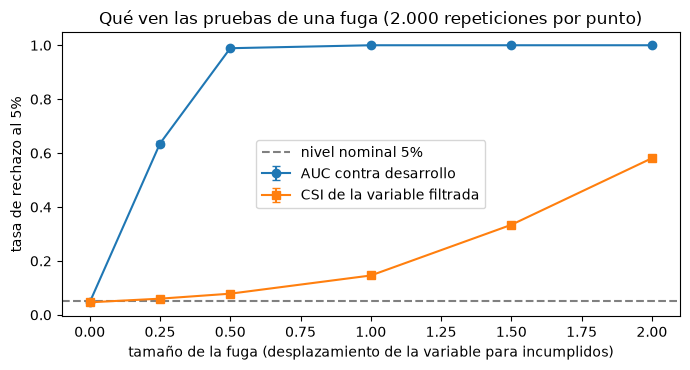

espécimen versionado de C22, fuga 1: p AUC vs desarrollo 4.56e-16 rojo | p CSI 0.639 verde
inflación exacta del AUC de desarrollo por una fuga de 1: 0.1499


In [9]:
# Leer las tasas de rechazo versionadas de las dos pruebas por tamaño de fuga y dibujarlas
sims = {s["key"]: s for s in c22["outputs"]["simulations"]}
leaks = c22["outputs"]["ladder"]["values"]
rows = []
print(f"{'fuga':>6s} {'repeticiones':>13s} {'AUC vs desarrollo':>22s} {'CSI de la variable filtrada':>34s}")
for x in leaks:
    tag = f"l{x:g}"
    a, f = sims[f"disc.auc_vs_initial@{tag}"], sims[f"stability.csi@{tag}"]
    rows.append((x, a["rates"]["p<0.05"], f["rates"]["p<0.05"]))
    print(f"{x:6.2f} {a['n_rep']:13d} {a['rates']['p<0.05']['rate']:14.3f} (se {a['rates']['p<0.05']['se']:.3f}) {f['rates']['p<0.05']['rate']:14.3f} (se {f['rates']['p<0.05']['se']:.3f})")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar([r[0] for r in rows], [r[1]["rate"] for r in rows], yerr=[r[1]["se"] for r in rows], marker="o", capsize=3, label="AUC contra desarrollo")
ax.errorbar([r[0] for r in rows], [r[2]["rate"] for r in rows], yerr=[r[2]["se"] for r in rows], marker="s", capsize=3, label="CSI de la variable filtrada")
ax.axhline(0.05, color="gray", linestyle="--", label="nivel nominal 5%")
ax.set_xlabel("tamaño de la fuga (desplazamiento de la variable para incumplidos)")
ax.set_ylabel("tasa de rechazo al 5%")
ax.set_title("Qué ven las pruebas de una fuga (2.000 repeticiones por punto)")
ax.legend()
fig.tight_layout()
plt.show()
specimen = {t["test_id"]: t for t in c22["tests"]}
print("espécimen versionado de C22, fuga 1: p AUC vs desarrollo", format(specimen["disc.auc_vs_initial"]["p_value"], ".3g"), LIGHT[specimen["disc.auc_vs_initial"]["light"]], "| p CSI", round(specimen["stability.csi"]["p_value"], 3), LIGHT[specimen["stability.csi"]["light"]])
exact_inflation = c22["impact"]["dev_auc_inflation_l1"]["value"]
print("inflación exacta del AUC de desarrollo por una fuga de 1:", round(exact_inflation, 4))


## Resultados

- **Las reglas son requisitos con compuertas.** CT-101 a CT-103 nombran cada uno la prueba que falla cuando se viola, las tres compuertas existen en `tests/test_leakage.py`, y pasaron (3 pasaron) en el entorno del pipeline cuando se reunió esta evidencia. Una regla escrita solo en un dossier sería la práctica de la investigación; estas son las reglas con una prueba que falla.
- **La división declarada está en los artefactos.** Para C01 los tres tramos particionan las 30.000 tarjetas, los conteos detrás de cada una de las 13 variables agrupadas suman solo las 16.800 tarjetas de entrenamiento, cada mapa de calibración se ajustó en el tramo de calibración y los tramos comparten una tasa de incumplimiento. Para los cinco horizontes y el archivo agrupado de C02 las cuatro marcas se cumplen y las filas particionan. Para C03 el objetivo se lee solo en una marca que ya pasó en la fecha del archivo, cada ventana de entrenamiento cierra antes de que empiece su cohorte de prueba, y FY2020 es el último año que puede probarse (su marca es 2025-09-30; la del año siguiente sería 2026-09-30, después de la fecha del archivo).
- **El protocolo declara sus límites.** C01 dice que no tiene validación fuera del tiempo, C02 rechaza una afirmación fuera del tiempo y rotula la transferencia como exploratoria, y C03 dice que sus datos son un programa federal, no la cartera de un banco. El cumplimiento se detiene donde se detienen los datos, y lo dice.
- **Para las pruebas, una fuga es una caída de la discriminación, no una deriva.** Con una fuga de 1 el AUC de desarrollo se infla en 0,15 (valor exacto 0,1499) y la prueba del AUC contra desarrollo es roja en la muestra del cuaderno (p cerca de 4e-15) y en las 2.000 repeticiones de C22 (tasa de rechazo 1,0), mientras que el índice de estabilidad de la variable filtrada casi no reacciona: ámbar en la muestra del cuaderno (p 0,046), verde en el espécimen versionado (p 0,64), y un rechazo en solo el 14,6% de las repeticiones. Sin fuga ambas pruebas conservan su tamaño (4,7% y 4,7%). La variable filtrada se mueve demasiado poco para verse como una deriva; se ve donde el modelo falla fuera del tiempo. Este es el hallazgo `F-LEAK-SIGNAL` de C22, y la razón del diseño: la compuerta debe detener la fuga antes de ajustar el modelo, porque las pruebas aplicadas después la ven solo a través del daño.

Lo que este cuaderno no muestra: no corre las compuertas, verifica las propiedades que ellas garantizan sobre los artefactos versionados, y la compuerta de invarianza (CT-103) no puede reproducirse en este entorno. La afirmación es cumplimiento de reglas conocidas, no un método nuevo: las reglas vienen de la investigación (dossier 04), y el marco de evaluación de Kozodoi et al. (2025) trata un problema distinto (sesgo de muestreo en la evaluación de solicitantes aceptados y rechazados). La fuga plantada es sintética, con un tipo de fuga (una variable que lleva el resultado en desarrollo); una fuga por tiempo (un valor fechado después de la fecha de observación) la cubre la compuerta CT-103, no esta demostración.

## Resumen

- BS-3: el protocolo a prueba de fuga se declara por caso y se hace cumplir con compuertas. Las reglas son conocidas (dossier 04); el producto agrega una prueba nombrada que falla para cada una (CT-101 a CT-103) y una división declarada y registrada para cada caso.
- Sobre los artefactos versionados, las propiedades de las compuertas se cumplen: transformaciones y conteos solo del tramo de entrenamiento, calibración en su propio tramo, marcas que rechazan una afirmación fuera del tiempo, y un objetivo leído solo donde es observable.
- El protocolo dice lo que cada división no puede afirmar: C01 no tiene validación fuera del tiempo, C02 no hace afirmación fuera del tiempo, C03 es un programa federal.
- Las pruebas ven una fuga como una caída de la discriminación fuera del tiempo, no como una deriva de la variable filtrada, y por eso hay que detenerla antes del ajuste.

**Qué probar después.** Lee `tests/test_leakage.py` completo y córrelo en el entorno del pipeline (`python -m pytest tests/test_leakage.py`); luego continúa con los otros temas, que aplican la misma disciplina a sus propias divisiones.

## Referencias

- Mavin, A., Wilkinson, P., Harwood, A. y Novak, M. (2009), Easy Approach to Requirements Syntax (EARS), 17th IEEE International Requirements Engineering Conference. https://doi.org/10.1109/RE.2009.9
- Kozodoi, N., Lessmann, S., Alamgir, M., Moreira-Matias, L. y Papakonstantinou, K. (2025), Fighting sampling bias: a framework for training and evaluating credit scoring models, European Journal of Operational Research 324(2). https://doi.org/10.1016/j.ejor.2025.01.040
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.5.4.1 y Anexo 3.1. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Tomczak, S. (2016), Polish Companies Bankruptcy, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- Este repositorio: los dossiers 04, 06 y 07 de la base de investigación (`docs/design/SDD.md`), `docs/design/features/c01-retail-pd/requirements.md`, `tests/test_leakage.py`.